<a href="https://colab.research.google.com/github/michelleuu/IAT360-Driver-Drowsiness-Computer-Vision-Project-/blob/main/DriverDrowsinessYolo8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## IAT 360 Final Project

In [1]:
%pip install ultralytics


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Import Libraries


In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from ultralytics import YOLO

Set dataset path

In [3]:
from pathlib import Path

dataset_path = Path("dataset")

print("Dataset exists:", dataset_path.exists())
print("Current working directory:", Path.cwd())

if dataset_path.exists():
    print("\nDataset contents:")
    for item in dataset_path.iterdir():
        print(item.name)

Dataset exists: True
Current working directory: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject

Dataset contents:
README.roboflow.txt
valid
.DS_Store
data.yaml
train


In [4]:
with open(dataset_path / "data.yaml", "r") as file:
    print(file.read())

train: train/images
val: valid/images
nc: 6
names:
- eye_closed
- eye_open
- head_dropped
- head_straight
- no_yawn
- yawn
roboflow:
  workspace: michelles-workspace-b7mvu
  project: kantukv2-hihkc
  version: 1
  license: CC BY 4.0
  url: https://app.roboflow.com/michelles-workspace-b7mvu/kantukv2-hihkc/1
path: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset



In [5]:
for split in ["train", "valid"]:
    image_folder = dataset_path / split / "images"
    label_folder = dataset_path / split / "labels"

    images = list(image_folder.glob("*.jpg")) + list(image_folder.glob("*.png"))
    labels = list(label_folder.glob("*.txt"))

    print(f"\n{split}:")
    print("Images:", len(images))
    print("Labels:", len(labels))


train:
Images: 3457
Labels: 3457

valid:
Images: 384
Labels: 384


Check class distribution

In [7]:
import yaml
from collections import Counter

# Read class names from data.yaml
with open(dataset_path / "data.yaml", "r") as file:
    config = yaml.safe_load(file)

# Count annotations for each class
class_counts = Counter()

for split in ["train", "valid"]:
    label_folder = dataset_path / split / "labels"

    for label_file in label_folder.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            if not line.strip():
                continue

            class_id = int(line.split()[0])
            class_counts[class_id] += 1

# Display class distribution
for class_id, class_name in enumerate(config["names"]):
    print(f"{class_name}: {class_counts[class_id]}")

eye_closed: 1773
eye_open: 2066
head_dropped: 1134
head_straight: 2707
no_yawn: 2201
yawn: 1638


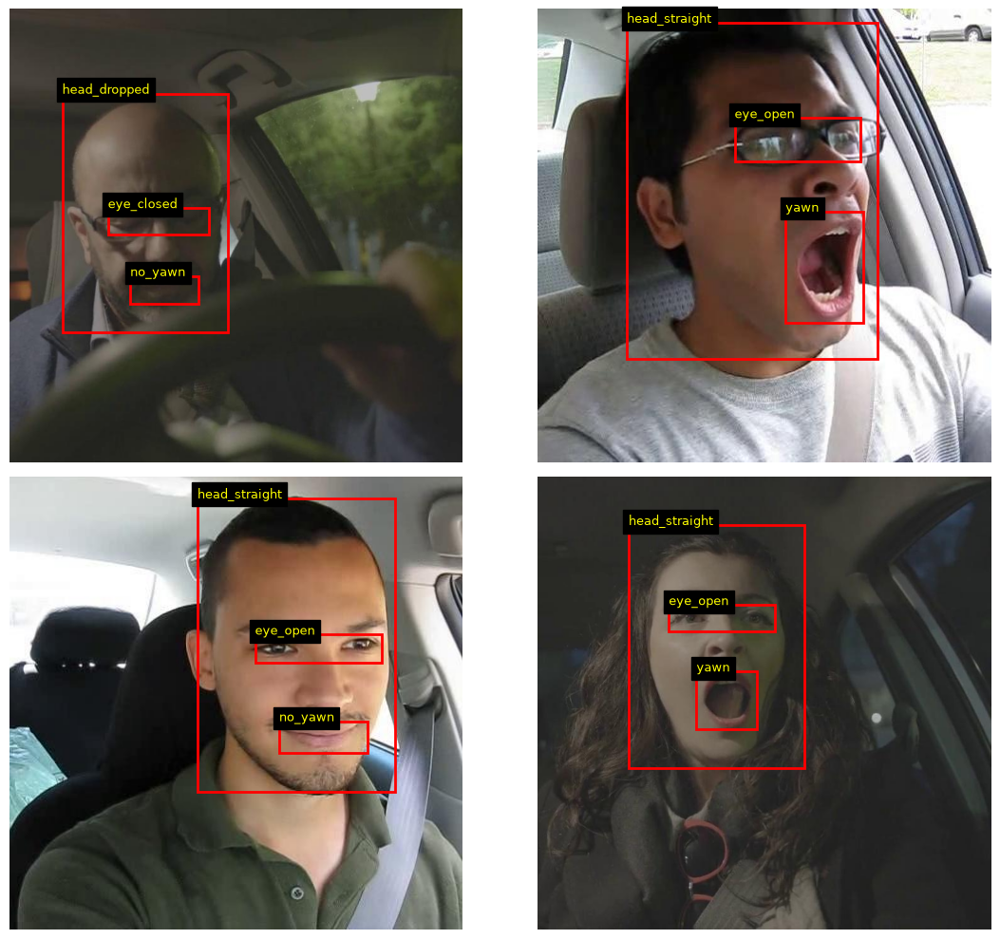

In [9]:
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Select 4 random training images
sample_images = random.sample(images, 4)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, image_path in zip(axes.flat, sample_images):
    image = Image.open(image_path)
    width, height = image.size

    ax.imshow(image)

    # Find the corresponding annotation file
    label_path = dataset_path / "train" / "labels" / (image_path.stem + ".txt")

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            class_id = int(values[0])
            x, y, w, h = map(float, values[1:5])

            # Convert YOLO coordinates to pixel coordinates
            x_min = (x - w / 2) * width
            y_min = (y - h / 2) * height

            # Draw bounding box
            rect = patches.Rectangle(
                (x_min, y_min),
                w * width,
                h * height,
                fill=False,
                edgecolor="red",
                linewidth=2
            )

            ax.add_patch(rect)
            ax.text(
                x_min,
                y_min,
                config["names"][class_id],
                color="yellow",
                fontsize=9,
                backgroundcolor="black"
            )

    ax.axis("off")

plt.tight_layout()
plt.show()

## Import yolo Model

In [10]:
from ultralytics import YOLO
model = YOLO("yolov8s.pt")
print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


### Train baseline YOLOv8 model

In [11]:
results = model.train(
    data=str(dataset_path / "data.yaml"),
    epochs=5,
    patience=5,
    batch=8,
    lr0=0.0005,
    imgsz=640,
    device="mps",
    project="Driver_Drowsiness",
    name="baseline",
    seed=42
)

New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        1/5      4.36G      1.403      1.634      1.502         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:24
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.2it/s 7.6s
                   all        380       1140      0.842      0.834      0.865      0.538

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        2/5      4.42G      1.135     0.7779       1.17         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        2/5      4.42G       1.23     0.8335      1.322         15        640: 100% ━━━━━━━━━━━━ 400/400 2.8it/s 2:25
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.1s
                   all        380       1140       0.85      0.837      0.905      0.582

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        3/5      4.43G      1.125     0.7068      1.253         24        640: 0% ──────────── 0/400  0.6s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        3/5      4.43G      1.169     0.7355      1.272         15        640: 100% ━━━━━━━━━━━━ 400/400 3.1it/s 2:08
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.7it/s 6.5s
                   all        380       1140      0.886      0.878      0.914      0.587

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        4/5      4.47G       1.06      0.652      1.244         24        640: 0% ──────────── 0/400  0.4s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        4/5      4.42G      1.126     0.6469      1.239         15        640: 100% ━━━━━━━━━━━━ 400/400 3.0it/s 2:13
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.4it/s 7.0s
                   all        380       1140      0.898      0.866      0.928      0.623

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
        5/5       4.4G      1.183     0.5937      1.183         24        640: 0% ──────────── 0/400  0.5s

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operatio

        5/5      5.36G      1.069     0.5741      1.196         15        640: 100% ━━━━━━━━━━━━ 400/400 3.0it/s 2:14
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 3.5it/s 6.9s
                   all        380       1140      0.905      0.919      0.949       0.64

5 epochs completed in 0.201 hours.
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/baseline-2/weights/last.pt, 22.5MB
Optimizer stripped from /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/baseline-2/weights/best.pt, 22.5MB

Validating /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/runs/detect/Driver_Drowsiness/baseline-2/weights/best.pt...
Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 MPS (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs

### Evaluate baseline performance

In [15]:
metrics = model.val(project="Driver_Drowsiness")  # no other arguments needed, dataset and settings remembered
metrics.box.map    # map50-95
metrics.box.map50  # map50
metrics.box.map75  # map75
metrics.box.maps   # a list contains map50-95 of each category
metrics.box.mp    # P
metrics.box.mr

Ultralytics 8.4.183 🚀 Python-3.14.7 torch-2.14.1 CPU (Apple M4 Pro)
Model summary (fused): 72 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.2±0.1 ms, read: 187.3±72.3 MB/s, size: 39.0 KB)
val: Scanning /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/labels.cache... 384 images, 0 backgrounds, 4 corrupt: 100% ━━━━━━━━━━━━ 384/384 76.7Mit/s 0.0s
val: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/images/cropped_53-2-_aug2_jpg.rf.a1d11dfa0d785d1dfff2453a8ede5057.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/images/cropped_63_aug0_jpg.rf.b3c870740ac87599a19796f0a4008ae2.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: /Users/michellezhu/Desktop/Fall 2026/IAT360 Codes/ComputerVisionFinalProject/dataset/valid/image

np.float64(0.9192037772529575)

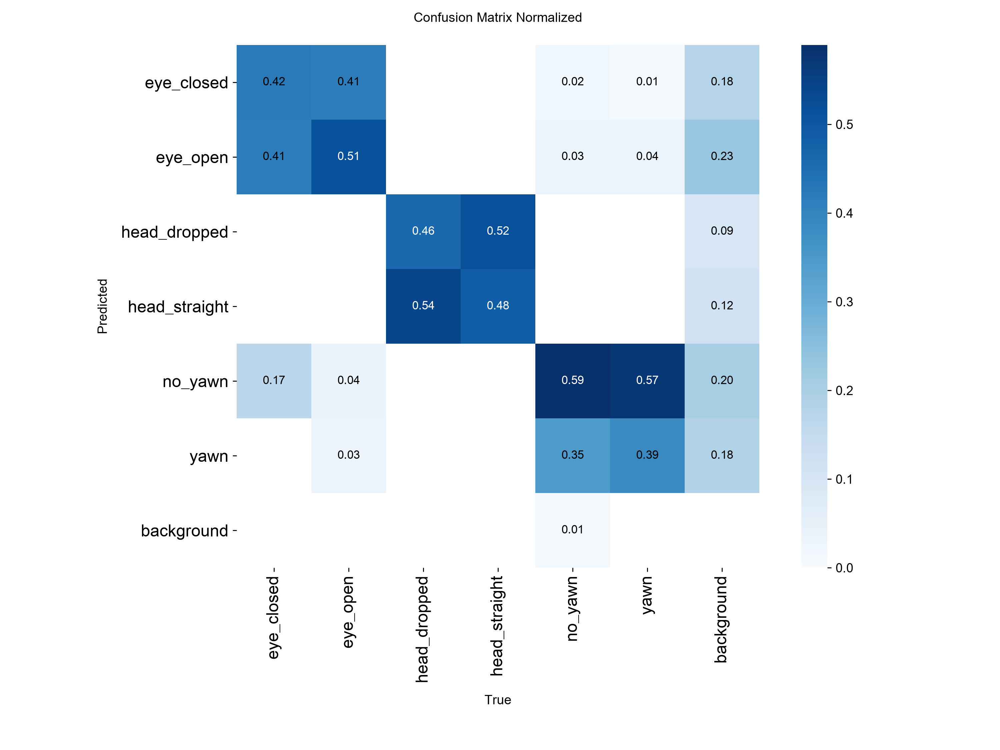

In [13]:
from PIL import Image
from IPython.display import display

display(Image.open(
    "runs/detect/Driver_Drowsiness/baseline-2/confusion_matrix_normalized.png"
))

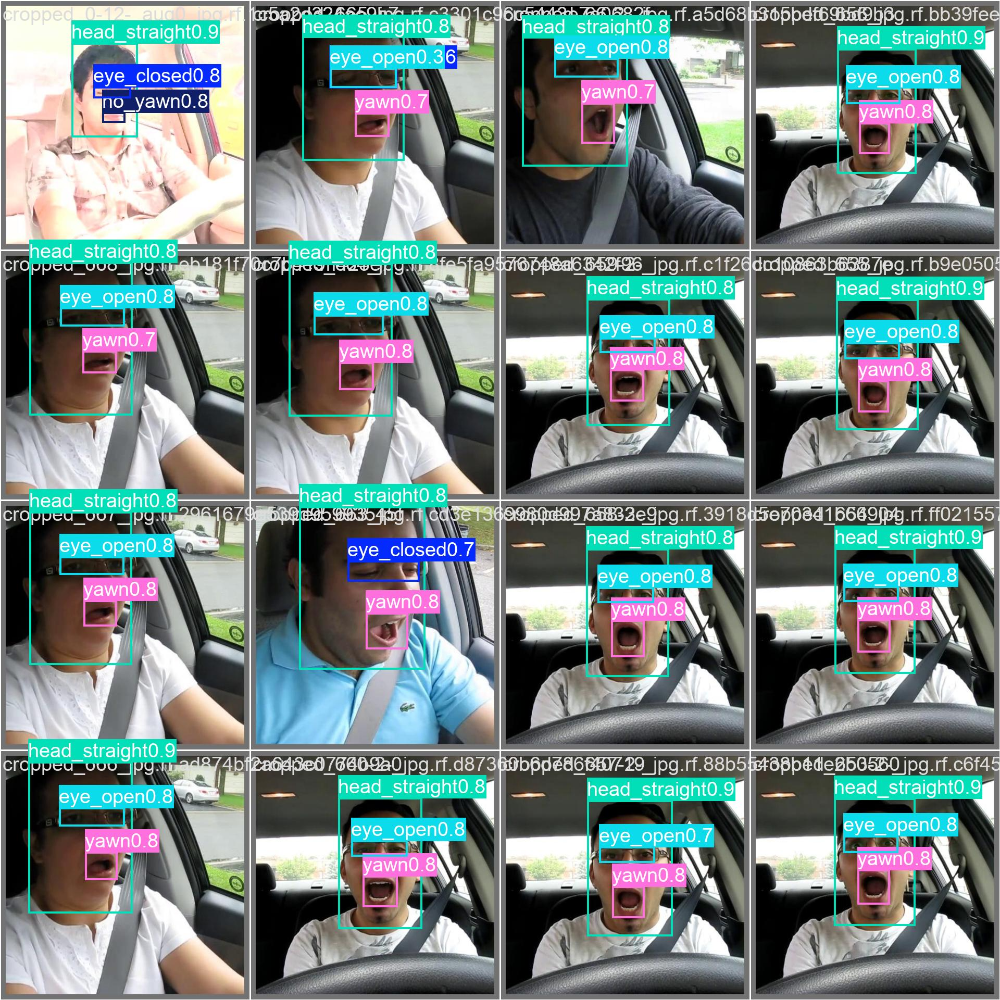

In [14]:
from PIL import Image
from IPython.display import display

display(Image.open(
    "runs/detect/Driver_Drowsiness/baseline-2/val_batch0_pred.jpg"
))